# Liveness Detection (Anti-Spoofing) — Training Notebook
**COS30082 Applied Machine Learning · Facial Recognition with Emotion & Liveness**

Trains a binary classifier **live (1) vs spoof (0)** with transfer learning (MobileNetV3-Large, partial fine-tuning, which the brief allows) on a laptop **RTX 5060 Mobile**.

**Pipeline**
1. Setup + GPU check
2. Data: Kaggle real faces + synthetic spoofs + (strongly recommended) your own webcam captures
3. Group-aware train/val/test split (no identity leakage)
4. Model, two-phase fine-tuning with mixed precision
5. Evaluation: ROC/AUC, EER, APCER / BPCER / ACER, confusion matrix, per-source accuracy
6. Grad-CAM, to see *what* the model looks at
7. Save model + live webcam demo for your attendance system

> ⚠️ **Important data caveat.** The Kaggle *11-785 HW2 Part 2* dataset contains **only real faces** (identities for verification). It has **no spoof samples**, and its images are small, aligned crops, which hides the texture cues (moiré, print grain) that liveness relies on. So this notebook:
> * simulates screen-replay and printed-photo attacks from the real faces (good for bootstrapping), **and**
> * lets you record **real webcam data** (live you vs phone-screen / printed-photo attacks). Your own captures are what make the model work in the real demo.

Dataset link: https://www.kaggle.com/competitions/11-785-fall-20-homework-2-part-2

## 1 · Setup
The **RTX 5060 is a Blackwell GPU (compute capability 12.0)**. It needs a PyTorch build with **CUDA 12.8+** (PyTorch ≥ 2.7). Older wheels will install fine but fail with *"no kernel image is available"*.
Uncomment and run the install line once, then restart the kernel.

In [2]:
# One-time install (Windows/Linux). cu128 wheels support Blackwell (sm_120).
# %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
%pip install opencv-python numpy pandas matplotlib scikit-learn tqdm pillow

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, random, time, json, math
from pathlib import Path
from collections import deque
from concurrent.futures import ThreadPoolExecutor

import numpy as np, pandas as pd, cv2
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

print("torch", torch.__version__, "| CUDA build:", torch.version.cuda)
assert torch.cuda.is_available(), "CUDA not available - install the cu128 PyTorch build (see above)."
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0), "| capability:", torch.cuda.get_device_capability(0))
print("bf16 supported:", torch.cuda.is_bf16_supported())
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

torch 2.11.0+cu128 | CUDA build: 12.8
GPU: NVIDIA GeForce RTX 5060 Laptop GPU | capability: (12, 0)
bf16 supported: True


## 2 · Configuration
Set `DATA_ROOT` to the folder that contains the Kaggle `classification_data/` directory.

Expected layout:
```
data/
  classification_data/train_data/<person_id>/*.jpg     <- Kaggle (real faces only)
  liveness/real/*.jpg      <- your webcam captures of live faces   (created by the collector below)
  liveness/spoof/*.jpg     <- your captures of phone-screen / printed-photo attacks
  liveness/synthetic/      <- auto-generated spoofs
```

In [4]:
DATA_ROOT   = Path("data")
KAGGLE_TRAIN = DATA_ROOT / "classification_data" / "train_data"
LIV_DIR     = DATA_ROOT / "liveness"
OWN_REAL    = LIV_DIR / "real"
OWN_SPOOF   = LIV_DIR / "spoof"
SYN_DIR     = LIV_DIR / "synthetic"
for d in (OWN_REAL, OWN_SPOOF, SYN_DIR): d.mkdir(parents=True, exist_ok=True)

IMG_SIZE       = 160      # network input. Higher = more texture detail, slower. 128-224 are sensible.
MAX_IDS        = 1500     # how many Kaggle identities to use
IMGS_PER_ID    = 4        # images per identity
OWN_REPEAT     = 5        # up-weight your own webcam data in the training split
BATCH_SIZE     = 128
PHASE1_EPOCHS  = 3        # head only
PHASE2_EPOCHS  = 12       # fine-tune last blocks
LR_HEAD, LR_FT = 1e-3, 2e-4
UNFREEZE_FROM  = 10       # MobileNetV3 features[10:] are fine-tuned in phase 2
NUM_WORKERS    = 0 if os.name == "nt" else 4   # Windows + notebooks: keep 0 (spawn/pickle issues)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

## 3 · (Highly recommended) Record your own webcam data
Synthetic spoofs only get you so far. Spend ~10 minutes here and the demo will be far more convincing.

* **`real`**: look at the webcam naturally. Vary lighting, distance, glasses, head angle. Do several **sessions** (e.g. `s1`, `s2`), because sessions are kept together when splitting so test results are honest.
* **`spoof`**: point the webcam at a **phone screen** (photo *and* video of a face), a **printed photo**, a **tablet/laptop screen**. Use faces of classmates or Kaggle images shown on your phone. Vary screen brightness and angle.

Controls: a window opens; press **q** to stop early.

In [16]:
import os, time, urllib.request
from pathlib import Path
import cv2, numpy as np
from IPython.display import display, update_display, Image as IPImage

# ---------- face detector (works on OpenCV 4.x and 5.x) ----------
_USE_CASCADE = hasattr(cv2, "CascadeClassifier")
if _USE_CASCADE:
    _p = Path(cv2.data.haarcascades + "haarcascade_frontalface_default.xml") if hasattr(cv2, "data") else Path("x")
    if not _p.exists():
        _p = Path("haarcascade_frontalface_default.xml")
        if not _p.exists():
            urllib.request.urlretrieve(
                "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml", _p)
    FACE_CASCADE = cv2.CascadeClassifier(str(_p))
    assert not FACE_CASCADE.empty(), "cascade failed to load"
    print("face detector: Haar cascade")
else:
    _m = Path("face_detection_yunet_2023mar.onnx")
    if not _m.exists():
        urllib.request.urlretrieve(
            "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx", _m)
    assert _m.stat().st_size > 100_000, "YuNet download looks wrong (file too small) - download it manually from the opencv_zoo repo"
    _yunet = cv2.FaceDetectorYN.create(str(_m), "", (320, 320), score_threshold=0.7)
    print("face detector: YuNet")

def detect_largest_face(img):
    # accepts a grayscale or BGR frame; returns (x, y, w, h) of the largest face, or None
    if _USE_CASCADE:
        gray = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = FACE_CASCADE.detectMultiScale(gray, scaleFactor=1.2, minNeighbors=5, minSize=(80, 80))
        return None if len(faces) == 0 else max(faces, key=lambda b: b[2] * b[3])
    bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR) if img.ndim == 2 else img
    _yunet.setInputSize((bgr.shape[1], bgr.shape[0]))
    _, faces = _yunet.detect(bgr)
    if faces is None: return None
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])[:4]
    return (max(int(x), 0), max(int(y), 0), int(w), int(h))

def crop_face(frame, box, margin=1.3):
    # square crop around the face with extra context (the same function is used at inference!)
    x, y, w, h = box
    cx, cy, s = x + w / 2, y + h / 2, max(w, h) * margin
    x0, y0 = int(max(cx - s / 2, 0)), int(max(cy - s / 2, 0))
    x1, y1 = int(min(cx + s / 2, frame.shape[1])), int(min(cy + s / 2, frame.shape[0]))
    return frame[y0:y1, x0:x1]

# ---------- inline collector (no pop-up window needed) ----------
def collect_inline(kind, session, n=300, every=4, cam=0, max_seconds=180):
    # kind: "real" or "spoof". Stop early with the notebook's Interrupt button.
    out = OWN_REAL if kind == "real" else OWN_SPOOF
    cap = cv2.VideoCapture(cam, cv2.CAP_DSHOW) if os.name == "nt" else cv2.VideoCapture(cam)
    if not cap.isOpened():
        raise RuntimeError("Camera not opened - close other apps using it, or try cam=1")
    saved, frame_i, first, t0 = 0, 0, True, time.time()
    try:
        while saved < n and time.time() - t0 < max_seconds:
            ok, frame = cap.read()
            if not ok: continue
            frame_i += 1
            box = detect_largest_face(frame)
            view = frame.copy()
            if box is not None:
                x, y, w, h = box
                cv2.rectangle(view, (x, y), (x + w, y + h), (0, 255, 0), 2)
                if frame_i % every == 0:
                    cv2.imwrite(str(out / f"{session}_{saved:04d}.jpg"), crop_face(frame, box),
                                [cv2.IMWRITE_JPEG_QUALITY, 95])
                    saved += 1
            cv2.putText(view, f"{kind} [{session}] {saved}/{n}", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
            img = IPImage(data=cv2.imencode(".jpg", view)[1].tobytes())
            if first: display(img, display_id="collector"); first = False
            else:     update_display(img, display_id="collector")
    finally:
        cap.release()
    print(f"saved {saved} images -> {out}")

# Run these one at a time (uncomment):
# collect_inline("real",  "s1", n=300)
# collect_inline("spoof", "p1", n=300)   # phone screen showing a face
# collect_inline("spoof", "p2", n=300)   # printed photo

face detector: YuNet


In [13]:
import cv2, sys
print("python :", sys.executable)
print("cv2    :", cv2.__version__, cv2.__file__)
print("has CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))
print("has FaceDetectorYN   :", hasattr(cv2, "FaceDetectorYN"))

python : d:\Anaconda\python.exe
cv2    : 5.0.0 d:\Anaconda\Lib\site-packages\cv2\__init__.py
has CascadeClassifier: False
has FaceDetectorYN   : True


## 4 · Synthetic spoof generator
Two attack simulators applied to real face crops:

| Attack | What is simulated |
|---|---|
| **Screen replay** | sub-pixel grid + moiré beating, colour cast / gamma change, glare, blur, sensor noise, phone **bezel** & perspective |
| **Printed photo** | desaturation, flat contrast, halftone dots, paper texture, uneven lighting, perspective / paper edge |

Both end with random JPEG compression. The training pipeline also applies random JPEG to *real* images, so the model can't cheat by learning "compressed = spoof".

In [5]:
def _grid(s):
    yy, xx = np.mgrid[0:s, 0:s].astype(np.float32)
    return xx, yy

def _bezel(img, rng, light=False):
    # shrink image into a coloured frame (phone bezel / paper margin) + slight perspective warp
    s = img.shape[0]
    pad = int(rng.uniform(0.04, 0.16) * s)
    col = int(rng.integers(215, 255)) if light else int(rng.integers(0, 45))
    frame = np.full((s, s, 3), col, np.uint8)
    inner = s - 2 * pad
    frame[pad:pad + inner, pad:pad + inner] = cv2.resize(img, (inner, inner))
    j = rng.uniform(0, 0.06) * s
    src = np.float32([[0, 0], [s, 0], [s, s], [0, s]])
    dst = src + rng.uniform(-j, j, src.shape).astype(np.float32)
    M = cv2.getPerspectiveTransform(src, dst)
    return cv2.warpPerspective(frame, M, (s, s), borderValue=(col, col, col))

def sim_screen(img, rng):
    s = img.shape[0]; xx, yy = _grid(s)
    out = img.astype(np.float32)
    ang = rng.uniform(0, np.pi)
    u = xx * np.cos(ang) + yy * np.sin(ang)
    out *= (1 + rng.uniform(0.03, 0.12) * np.sin(2 * np.pi * u / rng.uniform(2.0, 4.0)))[..., None]   # pixel grid
    out *= (1 + rng.uniform(0.02, 0.08) * np.sin(2 * np.pi * (xx * rng.uniform(.01, .05) + yy * rng.uniform(.01, .05))))[..., None]  # moire beat
    out *= rng.uniform(0.9, 1.1, size=3)                                          # colour cast
    out = 255 * (np.clip(out / 255, 0, 1) ** rng.uniform(0.8, 1.3))               # gamma
    cx, cy, r = rng.uniform(0, s), rng.uniform(0, s), rng.uniform(.15, .5) * s
    out += rng.uniform(0, 90) * np.exp(-((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * r * r))[..., None]  # glare
    k = int(rng.choice([1, 3, 5]))
    if k > 1: out = cv2.GaussianBlur(out, (k, k), 0)
    out += rng.normal(0, rng.uniform(1, 6), out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if rng.random() < 0.6: out = _bezel(out, rng, light=False)
    return out

def sim_print(img, rng):
    s = img.shape[0]; xx, yy = _grid(s)
    out = img.astype(np.float32)
    gray = out.mean(2, keepdims=True); a = rng.uniform(0, 0.5)
    out = a * gray + (1 - a) * out                                                  # faded colours
    out = (out - 128) * rng.uniform(0.6, 0.95) + 128 + rng.uniform(-20, 20)         # flat contrast
    p = rng.uniform(3, 6); a1, a2 = rng.uniform(0, np.pi, 2)
    ht = np.sin(2*np.pi*(xx*np.cos(a1)+yy*np.sin(a1))/p) * np.sin(2*np.pi*(xx*np.cos(a2)+yy*np.sin(a2))/p)
    out *= (1 + rng.uniform(0.04, 0.14) * ht)[..., None]                            # halftone
    paper = cv2.resize(rng.normal(0, 1, (s // 16 + 2, s // 16 + 2)).astype(np.float32), (s, s))
    out += paper[..., None] * rng.uniform(6, 18)                                    # paper texture
    out *= (1 + rng.uniform(-.25, .25) * ((xx / s) * np.cos(rng.uniform(0, 6.28)) + (yy / s) * np.sin(rng.uniform(0, 6.28))))[..., None]
    k = int(rng.choice([1, 3, 5]))
    if k > 1: out = cv2.GaussianBlur(out, (k, k), 0)
    out += rng.normal(0, rng.uniform(1, 5), out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if rng.random() < 0.5: out = _bezel(out, rng, light=True)
    return out

SPOOF_FNS = {"screen": sim_screen, "print": sim_print}

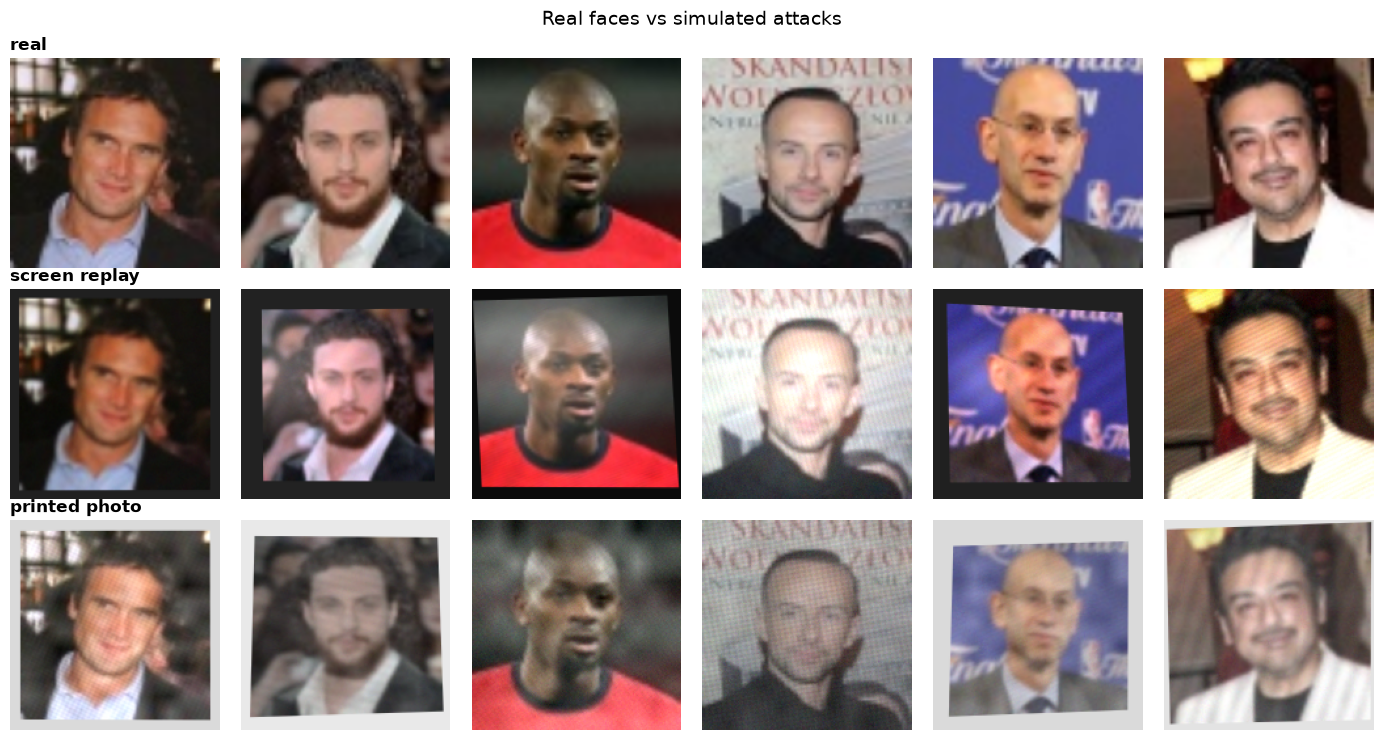

Original Kaggle image size: (64, 64) -> resized to 160


In [7]:
# Preview: original  |  screen replay  |  printed photo
kaggle_ids = sorted(os.listdir(KAGGLE_TRAIN)) if KAGGLE_TRAIN.exists() else []
assert kaggle_ids, f"No Kaggle data found at {KAGGLE_TRAIN} - check DATA_ROOT"
rng_prev = np.random.default_rng(0)
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for c in range(6):
    pid = kaggle_ids[c * 7]
    p = next((KAGGLE_TRAIN / pid).iterdir())
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE))
    for r, (name, im2) in enumerate([("real", im), ("screen replay", sim_screen(im, rng_prev)), ("printed photo", sim_print(im, rng_prev))]):
        axes[r, c].imshow(im2); axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(name, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Real faces vs simulated attacks", fontsize=14); plt.tight_layout(); plt.show()
print("Original Kaggle image size:", cv2.imread(str(p)).shape[:2], "-> resized to", IMG_SIZE)

## 5 · Build the dataset index and split by group
Every row has a `group` (identity or capture session). The split is done **by group**, so the same person or session never appears in both train and test, which prevents the model from memorising faces.

In [7]:
def make_synthetic(args):
    i, src, kind = args
    out = SYN_DIR / f"{kind}_{i:06d}.jpg"
    if out.exists(): return str(out)
    img = cv2.cvtColor(cv2.imread(str(src)), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    rng = np.random.default_rng(SEED + i)
    sp = SPOOF_FNS[kind](img, rng)
    cv2.imwrite(str(out), cv2.cvtColor(sp, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(60, 96))])
    return str(out)

rng = random.Random(SEED)
ids = rng.sample(kaggle_ids, min(MAX_IDS, len(kaggle_ids)))
rows = []
for pid in ids:
    files = sorted((KAGGLE_TRAIN / pid).iterdir())[:IMGS_PER_ID]
    for f in files:
        rows.append(dict(path=str(f), label=1, group=f"k_{pid}", source="kaggle_real"))
real_rows = list(rows)

jobs = [(i, r["path"], rng.choice(list(SPOOF_FNS))) for i, r in enumerate(real_rows)]
with ThreadPoolExecutor(8) as ex:
    outs = list(tqdm(ex.map(make_synthetic, jobs), total=len(jobs), desc="generating synthetic spoofs"))
for (i, src, kind), o, r in zip(jobs, outs, real_rows):
    rows.append(dict(path=o, label=0, group=r["group"], source=f"synth_{kind}"))

own_rows = []
for p in sorted(OWN_REAL.glob("*.jpg")):
    own_rows.append(dict(path=str(p), label=1, group="own_" + p.stem.split("_")[0], source="own_real"))
for p in sorted(OWN_SPOOF.glob("*.jpg")):
    own_rows.append(dict(path=str(p), label=0, group="own_" + p.stem.split("_")[0], source="own_spoof"))

df = pd.DataFrame(rows + own_rows)
print(f"{len(df)} samples | own webcam samples: {len(own_rows)}")
if not own_rows:
    print("⚠️  No own webcam data found - results will only reflect synthetic spoofs (see section 3).")
df.groupby(["source", "label"]).size().rename("count").reset_index()

generating synthetic spoofs:   0%|          | 0/6000 [00:00<?, ?it/s]

12000 samples | own webcam samples: 0
⚠️  No own webcam data found - results will only reflect synthetic spoofs (see section 3).


,source,label,count
0,kaggle_real,1,6000
1,synth_print,0,3040
2,synth_screen,0,2960


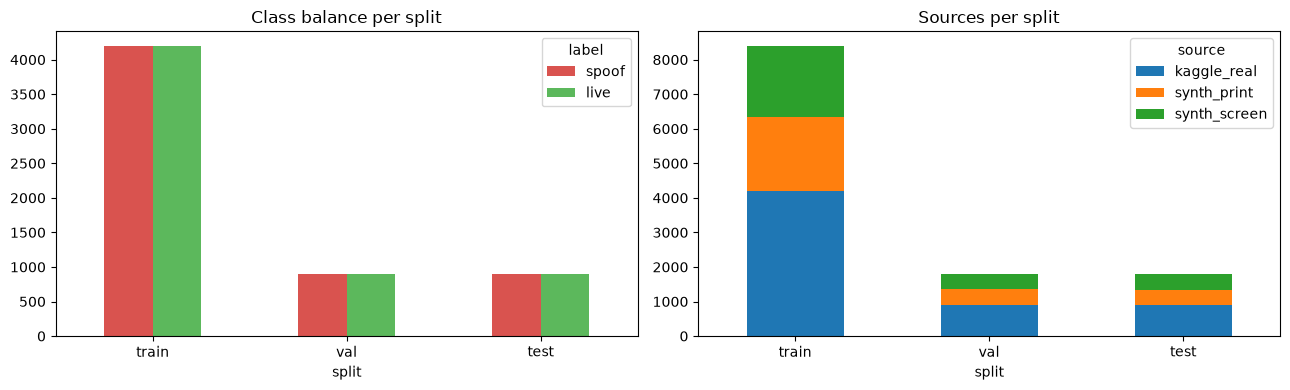

{'train': 8400, 'val': 1800, 'test': 1800}


In [8]:
def group_split(d, test_size, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(d, groups=d["group"]))
    return d.iloc[a], d.iloc[b]

train_df, tmp_df = group_split(df, 0.30, SEED)
val_df, test_df  = group_split(tmp_df, 0.50, SEED)

# up-weight your own webcam data in TRAIN only
own_train = train_df[train_df.source.str.startswith("own")]
if len(own_train): train_df = pd.concat([train_df] + [own_train] * (OWN_REPEAT - 1))
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

all_df = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"),
                    test_df.assign(split="test")], ignore_index=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(all_df.groupby(["split", "label"]).size().unstack(fill_value=0)
       .rename(columns={0: "spoof", 1: "live"}).loc[["train", "val", "test"]]
       .plot.bar(ax=ax[0], rot=0, color=["#d9534f", "#5cb85c"]))
ax[0].set_title("Class balance per split")
(pd.crosstab(all_df["split"], all_df["source"]).loc[["train", "val", "test"]]
   .plot.bar(stacked=True, ax=ax[1], rot=0))
ax[1].set_title("Sources per split"); plt.tight_layout(); plt.show()
print({k: len(v) for k, v in dict(train=train_df, val=val_df, test=test_df).items()})

## 6 · Dataset, augmentation and sample grid

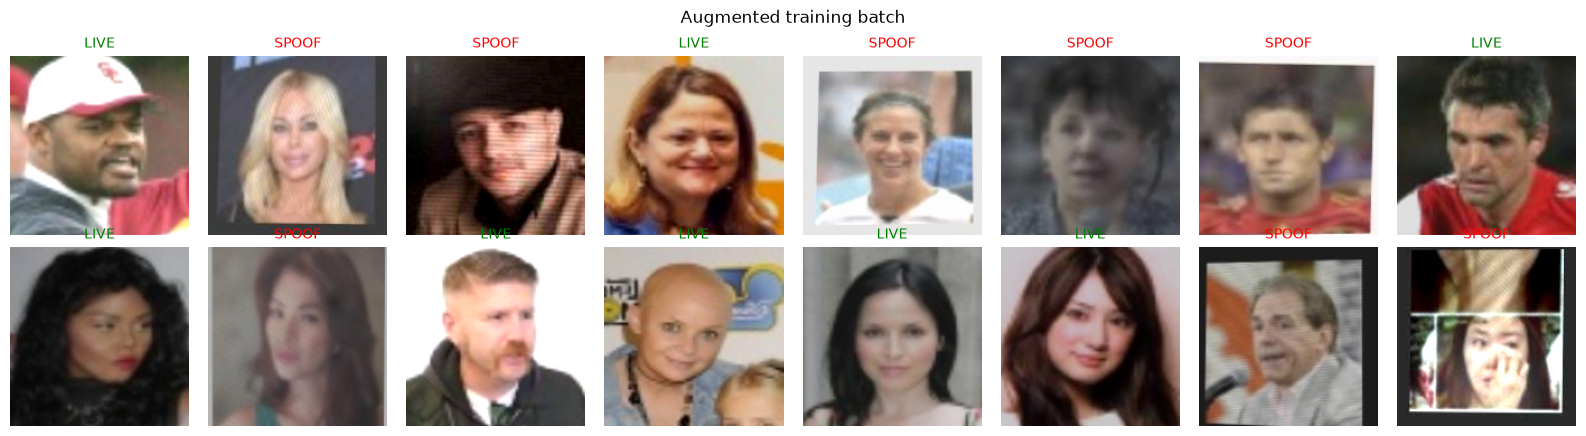

In [9]:
class RandomJPEG:
    # removes the "JPEG artefacts = spoof" shortcut by compressing real images too
    def __init__(self, p=0.5, q=(45, 95)): self.p, self.q = p, q
    def __call__(self, img):
        if random.random() > self.p: return img
        import io; buf = io.BytesIO(); img.save(buf, "JPEG", quality=random.randint(*self.q)); buf.seek(0)
        return Image.open(buf).convert("RGB")

train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    RandomJPEG(0.5),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.25, 0.25, 0.15),
    T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

class LivenessDS(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d.reset_index(drop=True), tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        return self.tf(Image.open(r.path).convert("RGB")), torch.tensor(r.label, dtype=torch.float32)

mk = lambda d, tf, sh: DataLoader(LivenessDS(d, tf), batch_size=BATCH_SIZE, shuffle=sh, num_workers=NUM_WORKERS,
                                   pin_memory=True, persistent_workers=NUM_WORKERS > 0, drop_last=sh)
train_dl, val_dl, test_dl = mk(train_df, train_tf, True), mk(val_df, eval_tf, False), mk(test_df, eval_tf, False)

def denorm(x): return (x.cpu() * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()
xb, yb = next(iter(train_dl))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, x, y in zip(axes.ravel(), xb, yb):
    ax.imshow(denorm(x)); ax.axis("off"); ax.set_title("LIVE" if y > .5 else "SPOOF", color="green" if y > .5 else "red", fontsize=10)
plt.suptitle("Augmented training batch"); plt.tight_layout(); plt.show()

## 7 · Model: MobileNetV3-Large with partial fine-tuning
* ImageNet-pretrained backbone → **we always train further** (head first, then the last blocks), which satisfies the "no fully pre-trained models" rule.
* Output: a single **logit**; `sigmoid(logit)` = probability the face is **live**.
* Loss: `BCEWithLogitsLoss`. Mixed precision (**bf16**), which the RTX 5060 supports. `channels_last` for speed.

In [11]:
def build_model():
    m = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)
    m.classifier = nn.Sequential(nn.Linear(960, 256), nn.Hardswish(), nn.Dropout(0.3), nn.Linear(256, 1))
    return m

def set_trainable(m, from_block):
    # blocks with index >= from_block (and the classifier) are trainable
    for i, blk in enumerate(m.features):
        for p in blk.parameters(): p.requires_grad = i >= from_block
    for p in m.classifier.parameters(): p.requires_grad = True
    n_tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"trainable params: {n_tr/1e6:.2f}M / {sum(p.numel() for p in m.parameters())/1e6:.2f}M")

model = build_model().to(DEVICE).to(memory_format=torch.channels_last)
criterion = nn.BCEWithLogitsLoss()

In [11]:
@torch.no_grad()
def predict(m, loader):
    m.eval(); ps, ys = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            lo = m(x).squeeze(1)
        ps.append(torch.sigmoid(lo.float()).cpu()); ys.append(y)
    return torch.cat(ps).numpy(), torch.cat(ys).numpy()

def run_epoch(m, loader, opt=None, sched=None):
    m.train()
    tot, correct, n = 0.0, 0, 0
    for x, y in tqdm(loader, leave=False):
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last); y = y.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            lo = m(x).squeeze(1)
        loss = criterion(lo.float(), y)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if sched: sched.step()
        tot += loss.item() * len(y); n += len(y); correct += ((lo > 0).float() == y).sum().item()
    return tot / n, correct / n

history = {"tr_loss": [], "tr_acc": [], "va_loss": [], "va_acc": [], "va_auc": [], "phase": []}
best = dict(auc=-1, state=None)

def fit(epochs, lr, from_block, phase):
    global best
    set_trainable(model, from_block)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_dl), pct_start=0.2)
    for ep in range(epochs):
        t0 = time.time()
        tl, ta = run_epoch(model, train_dl, opt, sched)
        pv, yv = predict(model, val_dl)
        vl = F.binary_cross_entropy(torch.tensor(pv).clamp(1e-6, 1 - 1e-6), torch.tensor(yv)).item()
        va = ((pv > .5) == yv).mean(); auc = roc_auc_score(yv, pv)
        for k, v in zip(history, [tl, ta, vl, va, auc, phase]): history[k].append(v)
        if auc > best["auc"]:
            best = dict(auc=auc, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        print(f"[{phase}] ep {ep+1:02d}/{epochs} | {time.time()-t0:5.1f}s | train loss {tl:.4f} acc {ta:.3f} "
              f"| val loss {vl:.4f} acc {va:.3f} AUC {auc:.4f}")

## 8 · Train (phase 1: head only → phase 2: fine-tune last blocks)

In [12]:
fit(PHASE1_EPOCHS, LR_HEAD, from_block=99,            phase="head")
fit(PHASE2_EPOCHS, LR_FT,   from_block=UNFREEZE_FROM, phase="finetune")
model.load_state_dict(best["state"]); print("\nLoaded best checkpoint, val AUC =", round(best["auc"], 4))

trainable params: 0.25M / 3.22M


  0%|          | 0/65 [00:00<?, ?it/s]

[head] ep 01/3 | 108.1s | train loss 0.3871 acc 0.838 | val loss 0.4067 acc 0.827 AUC 0.9592


  0%|          | 0/65 [00:00<?, ?it/s]

[head] ep 02/3 |  22.3s | train loss 0.1668 acc 0.936 | val loss 0.1445 acc 0.944 AUC 0.9895


  0%|          | 0/65 [00:00<?, ?it/s]

... (21 outputs left out)

  0%|          | 0/65 [00:00<?, ?it/s]

[finetune] ep 11/12 |  27.5s | train loss 0.0082 acc 0.997 | val loss 0.0121 acc 0.996 AUC 1.0000


  0%|          | 0/65 [00:00<?, ?it/s]

[finetune] ep 12/12 |  27.6s | train loss 0.0068 acc 0.998 | val loss 0.0130 acc 0.996 AUC 1.0000

Loaded best checkpoint, val AUC = 1.0


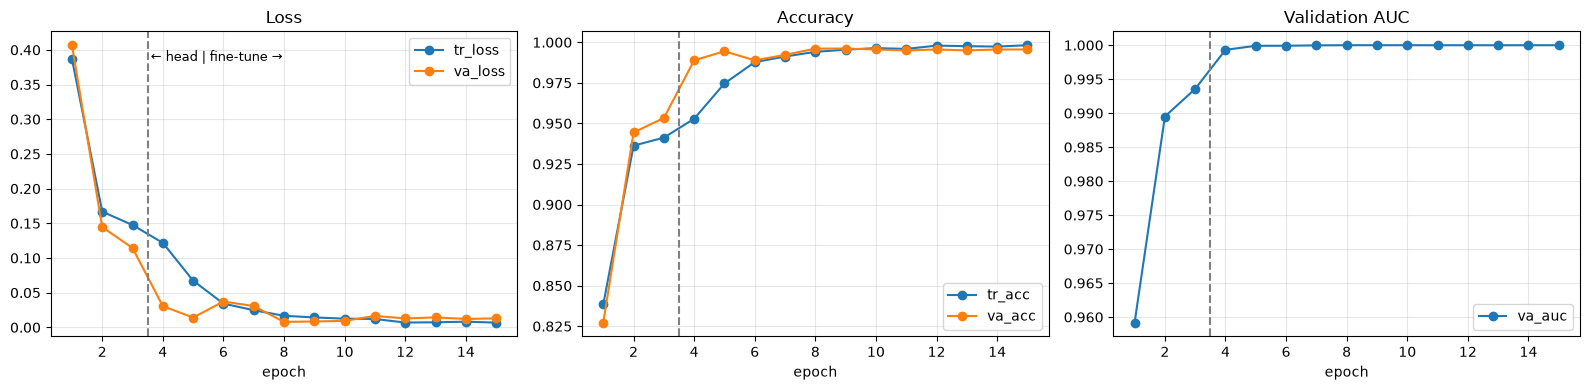

In [13]:
h = pd.DataFrame(history); h.index += 1
n1 = PHASE1_EPOCHS
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, cols, t in zip(ax, [["tr_loss", "va_loss"], ["tr_acc", "va_acc"], ["va_auc"]], ["Loss", "Accuracy", "Validation AUC"]):
    h[cols].plot(ax=a, marker="o"); a.axvline(n1 + .5, color="grey", ls="--"); a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].text(n1 + .6, ax[0].get_ylim()[1] * .9, "← head | fine-tune →", fontsize=9)
plt.tight_layout(); plt.show()

## 9 · Evaluation
Standard presentation-attack-detection metrics (ISO/IEC 30107-3):

* **APCER**: fraction of *spoofs accepted as live* (security hole)
* **BPCER**: fraction of *live faces rejected* (annoyance)
* **ACER** = (APCER + BPCER) / 2
* **EER**: error rate where APCER = BPCER

The decision threshold is chosen **on the validation set** (at EER) and then applied to the untouched test set.

threshold (val EER point): 0.978
TEST  AUC 1.0000 | EER 0.28% | APCER 0.33% | BPCER 0.22% | ACER 0.28%


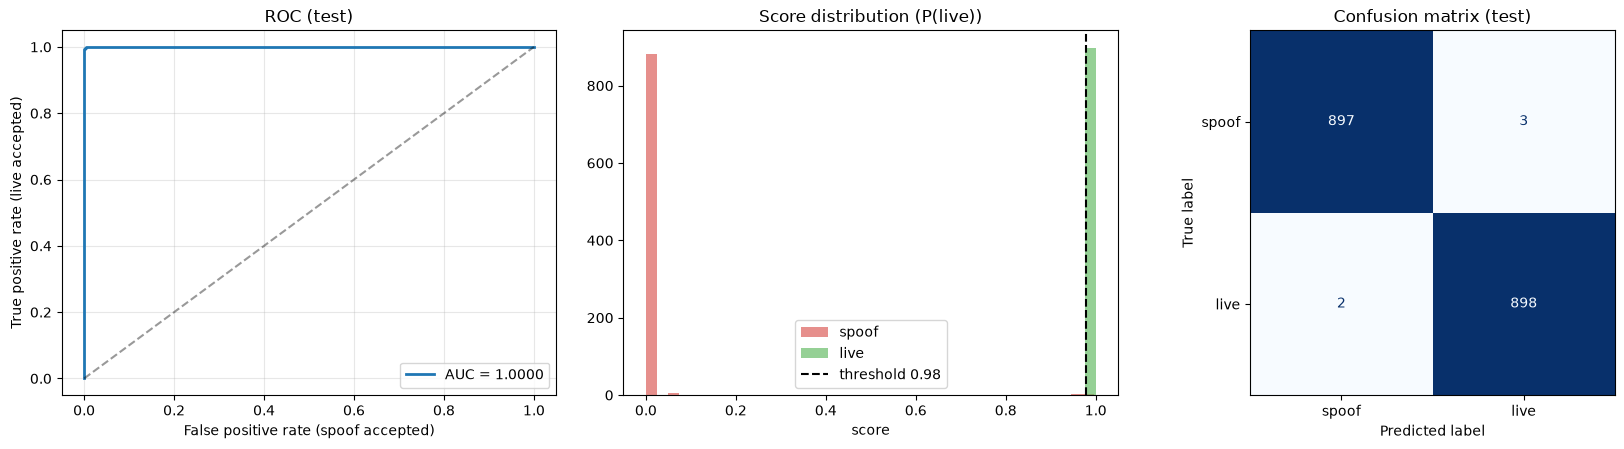

In [14]:
def eer_and_threshold(y, s):
    fpr, tpr, thr = roc_curve(y, s); fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr)); return (fpr[i] + fnr[i]) / 2, float(thr[i])

def pad_metrics(y, s, thr):
    spoof, live = s[y == 0], s[y == 1]
    apcer = (spoof >= thr).mean(); bpcer = (live < thr).mean()
    return apcer, bpcer, (apcer + bpcer) / 2

pv, yv = predict(model, val_dl); eer_v, THR = eer_and_threshold(yv, pv)
pt, yt = predict(model, test_dl)
auc_t = roc_auc_score(yt, pt); eer_t, _ = eer_and_threshold(yt, pt)
apcer, bpcer, acer = pad_metrics(yt, pt, THR)
print(f"threshold (val EER point): {THR:.3f}")
print(f"TEST  AUC {auc_t:.4f} | EER {eer_t*100:.2f}% | APCER {apcer*100:.2f}% | BPCER {bpcer*100:.2f}% | ACER {acer*100:.2f}%")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
fpr, tpr, _ = roc_curve(yt, pt)
ax[0].plot(fpr, tpr, lw=2, label=f"AUC = {auc_t:.4f}"); ax[0].plot([0, 1], [0, 1], "k--", alpha=.4)
ax[0].set(xlabel="False positive rate (spoof accepted)", ylabel="True positive rate (live accepted)", title="ROC (test)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].hist(pt[yt == 0], bins=40, alpha=.65, color="#d9534f", label="spoof"); ax[1].hist(pt[yt == 1], bins=40, alpha=.65, color="#5cb85c", label="live")
ax[1].axvline(THR, color="k", ls="--", label=f"threshold {THR:.2f}"); ax[1].set(title="Score distribution (P(live))", xlabel="score"); ax[1].legend()
ConfusionMatrixDisplay(confusion_matrix(yt, pt >= THR), display_labels=["spoof", "live"]).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title("Confusion matrix (test)"); plt.tight_layout(); plt.show()

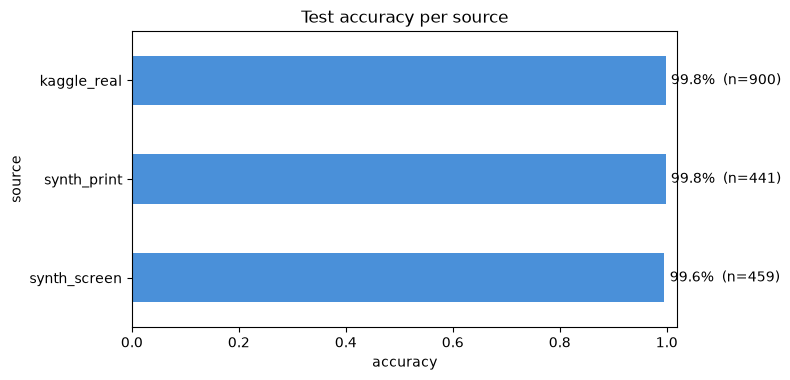

⚠️ No own-webcam data in test split: synthetic-only accuracy overestimates real-world performance.


In [15]:
# Where does the model fail? Accuracy per attack source on the test split.
t = test_df.copy(); t["score"] = pt; t["pred_live"] = t.score >= THR
t["correct"] = t.pred_live == (t.label == 1)
acc_src = t.groupby("source").correct.agg(["mean", "count"]).sort_values("mean")
ax = acc_src["mean"].plot.barh(figsize=(8, 3 + .3 * len(acc_src)), color="#4a90d9"); ax.set_xlim(0, 1.02)
for i, (m_, c) in enumerate(zip(acc_src["mean"], acc_src["count"])): ax.text(m_ + .01, i, f"{m_:.1%}  (n={c})", va="center")
ax.set_title("Test accuracy per source"); ax.set_xlabel("accuracy"); plt.tight_layout(); plt.show()
if not any(t.source.str.startswith("own")):
    print("⚠️ No own-webcam data in test split: synthetic-only accuracy overestimates real-world performance.")

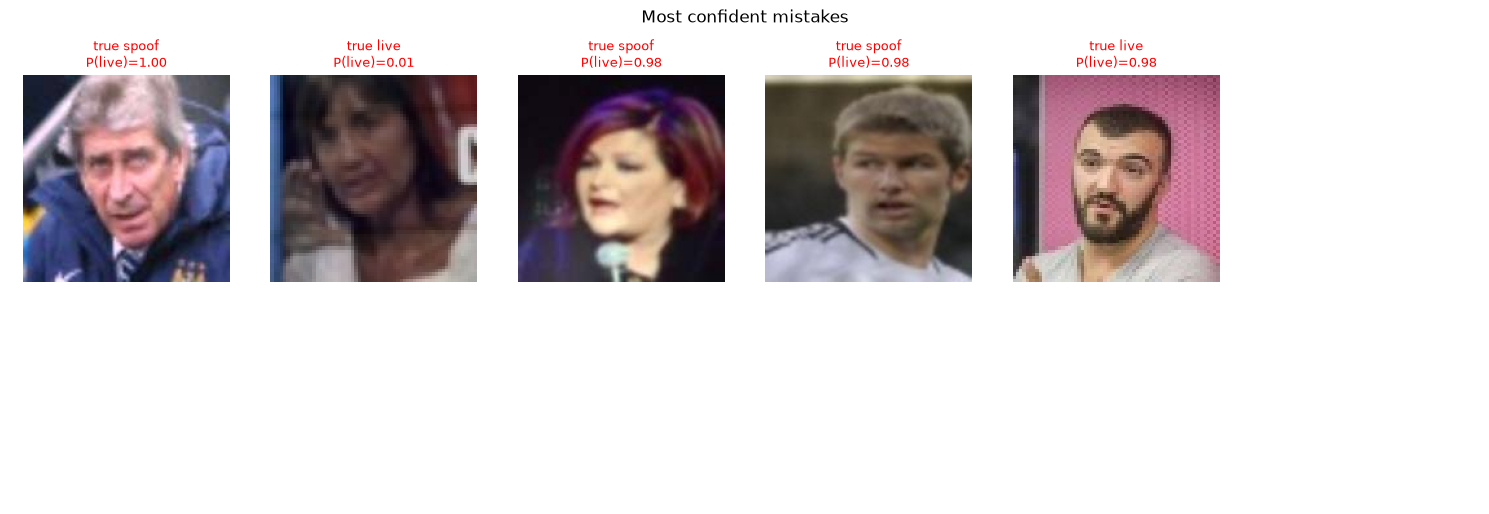

In [16]:
# Visual error analysis: worst mistakes
wrong = t[~t.correct].assign(err=lambda d: (d.score - d.label).abs()).sort_values("err", ascending=False).head(12)
if len(wrong):
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
    for ax, (_, r) in zip(axes.ravel(), wrong.iterrows()):
        ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
        ax.set_title(f"true {'live' if r.label else 'spoof'}\nP(live)={r.score:.2f}", fontsize=9, color="red")
    for ax in axes.ravel()[len(wrong):]: ax.axis("off")
    plt.suptitle("Most confident mistakes"); plt.tight_layout(); plt.show()
else: print("No test errors 🎉 (be suspicious - check the data caveat at the top)")

## 10 · Grad-CAM: what is the model looking at?
Useful for your report. Good liveness models should react to moiré, bezels, glare and print texture, **not** to the identity of the face.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.010784313082695007..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.008627466857433319..1.000000011920929].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0021568462252616882..1.000000011920929].


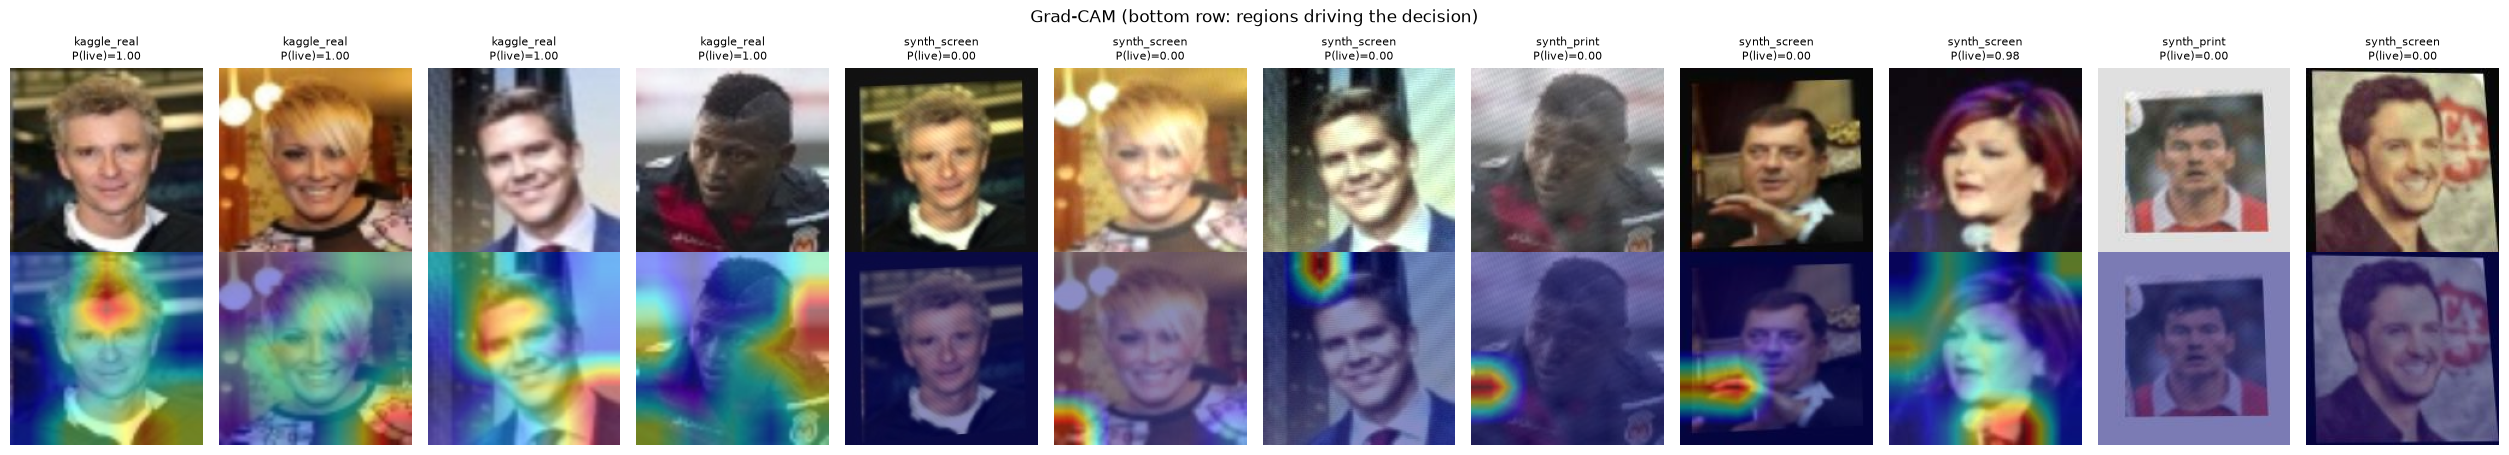

In [17]:
def grad_cam(m, x):
    # x: (1,3,H,W) normalised tensor. Returns heatmap in [0,1] and P(live)
    store = {}
    def fh(mod, i, o):
        store["a"] = o; o.register_hook(lambda g: store.__setitem__("g", g))
    hdl = m.features[-1].register_forward_hook(fh)
    m.eval(); x = x.to(DEVICE).requires_grad_(True)
    out = m(x).squeeze(); m.zero_grad(); out.backward()
    hdl.remove()
    w = store["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), torch.sigmoid(out).item()

samples = pd.concat([t[t.label == 1].sample(min(4, (t.label == 1).sum()), random_state=1),
                     t[t.label == 0].sample(min(8, (t.label == 0).sum()), random_state=1)])
fig, axes = plt.subplots(2, len(samples), figsize=(2.1 * len(samples), 4.6))
for j, (_, r) in enumerate(samples.iterrows()):
    img = Image.open(r.path).convert("RGB"); x = eval_tf(img).unsqueeze(0)
    cam, p = grad_cam(model, x); base = denorm(x[0])
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1] / 255.
    axes[0, j].imshow(base); axes[0, j].axis("off"); axes[0, j].set_title(f"{r.source}\nP(live)={p:.2f}", fontsize=8)
    axes[1, j].imshow(.55 * base + .45 * heat); axes[1, j].axis("off")
plt.suptitle("Grad-CAM (bottom row: regions driving the decision)"); plt.tight_layout(); plt.show()

## 11 · Save the model for your attendance system

In [18]:
SAVE_PATH = Path("liveness_mobilenetv3.pt")
torch.save({"state_dict": model.state_dict(), "threshold": THR, "img_size": IMG_SIZE,
            "mean": MEAN, "std": STD, "arch": "mobilenet_v3_large",
            "test_auc": float(auc_t), "test_acer": float(acer)}, SAVE_PATH)
print("saved", SAVE_PATH.resolve())

# Optional: ONNX export (for lighter deployment)
# dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
# torch.onnx.export(model.eval(), dummy, "liveness.onnx", input_names=["x"], output_names=["logit"], opset_version=17)

saved D:\COS30082_Applied Machine Learning\Group\liveness_mobilenetv3.pt


In [9]:
# How to load it inside your main app (copy into your project):
def load_liveness(path="liveness_mobilenetv3.pt", device="cuda"):
    ck = torch.load(path, map_location=device)
    m = build_model(); m.load_state_dict(ck["state_dict"]); m.to(device).eval()
    tf = T.Compose([T.Resize((ck["img_size"],) * 2), T.ToTensor(), T.Normalize(ck["mean"], ck["std"])])
    return m, tf, ck["threshold"]

@torch.no_grad()
def liveness_score(m, tf, bgr_face, device="cuda"):
    x = tf(Image.fromarray(cv2.cvtColor(bgr_face, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(device)
    return torch.sigmoid(m(x)).item()      # P(live)

## 12 · Live webcam demo
Green = **LIVE**, red = **SPOOF**, smoothed over the last few frames to avoid flicker. Test it with your phone showing a face and a printed photo. Press **q** to quit.

If it misclassifies your setup, record more `real` / `spoof` sessions in your conditions (section 3), rerun sections 5 to 11, and the model will adapt.

In [19]:
def live_demo(model_path="liveness_mobilenetv3.pt", cam=0, smooth=7):
    m, tf, thr = load_liveness(model_path, "cuda")
    cap = cv2.VideoCapture(cam, cv2.CAP_DSHOW) if os.name == "nt" else cv2.VideoCapture(cam)
    hist = deque(maxlen=smooth)
    try:
        while True:
            ok, frame = cap.read()
            if not ok: break
            box = detect_largest_face(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
            if box is not None:
                hist.append(liveness_score(m, tf, crop_face(frame, box)))
                p = float(np.mean(hist)); live = p >= thr
                col = (0, 200, 0) if live else (0, 0, 255)
                x, y, w, h = box
                cv2.rectangle(frame, (x, y), (x + w, y + h), col, 3)
                cv2.putText(frame, f"{'LIVE' if live else 'SPOOF'}  P(live)={p:.2f}", (x, max(y - 10, 20)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.9, col, 2)
            else: hist.clear()
            cv2.imshow("Liveness demo (q to quit)", frame)
            if cv2.waitKey(1) & 0xFF == ord("q"): break
    finally:
        cap.release(); cv2.destroyAllWindows(); cv2.waitKey(1)

live_demo()

## 13 · Notes for your report
* **Method**: transfer learning (MobileNetV3-Large, ImageNet init) with two-phase partial fine-tuning, BCE loss, AdamW + OneCycle, bf16 AMP.
* **Data**: Kaggle real faces + simulated screen/print attacks + self-recorded webcam sessions; group-wise splits (identity / session) to avoid leakage.
* **Metrics**: AUC, EER, APCER, BPCER, ACER, with the threshold fixed on validation.
* **Limitations to discuss**: synthetic-to-real domain gap, shortcut learning (resolution / JPEG), no 3D-mask or video-replay-with-motion coverage, single-frame decision (could add temporal smoothing or blink / head-motion challenge as your *innovative feature*).
* **Ideas to extend**: add a frequency-domain input (FFT / LBP) branch, train with more spoof sessions, add temporal model across frames, or a challenge-response check (blink / turn head).